# Hanle ERA5 vs Published AWS Ground-Based Wind Aligned Comparison

This notebook performs an hour-by-hour aligned comparison between **ERA5 10m wind speed** and **Hanle ground-based weather station observations** for the years 2020 through 2025. 

To make the datasets directly comparable and memory-efficient:
1. **Real Data**: The 5-second ground observations are resampled to hourly averages (including components `u` and `v`).
2. **ERA5 Data**: Wind speed and direction are extracted at the nearest grid point to Hanle site (lat: `32.779`, lon: `78.964`).
3. **Alignment**: The datasets are aligned on their UTC timestamps, ensuring that only times where both datasets have valid values are compared.

In [1]:
# ============================================================
# 1. IMPORTS & CONFIGURATION
# ============================================================
import os
import glob
import gc
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

plt.style.use('default')
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

HANLE_LAT = 32.779
HANLE_LON = 78.964

ERA5_DIR = r"../../data/raw/HN Data Monthly"
REAL_DIR = r"../../data/processed/hanle_published"
OUTPUT_DIR = r"../../data/exports"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Libraries and config loaded successfully! [OK]")

Libraries and config loaded successfully! [OK]


In [2]:
# ============================================================
# 2. LOAD AND HOURLY RESAMPLE REAL DATA (2020-2025)
# ============================================================
print("Loading and hourly resampling Real AWS observations...")
real_files = sorted(glob.glob(os.path.join(REAL_DIR, "hanle_published_*.csv")))
print(f"Found {len(real_files)} CSV files.")

hourly_records = []
for f in real_files:
    # datetime_utc is the UTC time coordinate
    df_m = pd.read_csv(f, usecols=['datetime_utc', 'wind_speed', 'u', 'v'])
    df_m['datetime_utc'] = pd.to_datetime(df_m['datetime_utc'])
    df_m = df_m.set_index('datetime_utc')
    
    # Resample to hourly averages (using '1h' instead of '1H' for newer pandas versions)
    u_h = df_m['u'].resample('1h').mean()
    v_h = df_m['v'].resample('1h').mean()
    speed_h = df_m['wind_speed'].resample('1h').mean()
    
    df_h = pd.DataFrame({
        'speed': speed_h,
        'u': u_h,
        'v': v_h
    }).dropna(subset=['speed'])
    
    hourly_records.append(df_h)
    del df_m
    gc.collect()

df_real = pd.concat(hourly_records)
# Recalculate direction from hourly mean components
df_real['direction'] = (270 - np.degrees(np.arctan2(df_real['v'], df_real['u']))) % 360
df_real = df_real.reset_index().rename(columns={'datetime_utc': 'datetime'})

print(f"Created {len(df_real):,} hourly ground-based records.")
print(df_real.head())

Loading and hourly resampling Real AWS observations...
Found 67 CSV files.


Created 46,979 hourly ground-based records.
             datetime      speed         u          v   direction
0 2020-01-01 11:00:00  14.712121  8.292671  12.109681  214.403219
1 2020-01-01 12:00:00  13.395694  8.184685  10.518185  217.888134
2 2020-01-01 13:00:00  11.298056  6.961320   8.849311  218.190400
3 2020-01-01 14:00:00   2.147500  0.469460   1.616924  196.190199
4 2020-01-01 15:00:00   1.111250  0.471625   0.655757  215.723987


In [3]:
# ============================================================
# 3. LOAD ERA5 DATA FOR HANLE SITE (2020-2025)
# ============================================================
print("Loading ERA5 NetCDF files for Hanle site...")
era5_files = sorted(glob.glob(os.path.join(ERA5_DIR, "india_*.nc")))
print(f"Found {len(era5_files)} NetCDF files.")

era5_records = []
for f in era5_files:
    with xr.open_dataset(f) as ds:
        # Select nearest grid point to Hanle site
        point_ds = ds.sel(latitude=HANLE_LAT, longitude=HANLE_LON, method='nearest')
        u10 = point_ds['u10'].values
        v10 = point_ds['v10'].values
        valid_time = pd.to_datetime(point_ds['valid_time'].values)
        
        # Wind Speed and Meteorological Wind Direction (from which wind is blowing)
        speed = np.sqrt(u10**2 + v10**2)
        direction = (270 - np.degrees(np.arctan2(v10, u10))) % 360
        
        df_pt = pd.DataFrame({
            'datetime': valid_time,
            'era5_speed': speed,
            'era5_u': u10,
            'era5_v': v10,
            'era5_direction': direction
        })
        era5_records.append(df_pt)

df_era5 = pd.concat(era5_records, ignore_index=True)
print(f"Loaded {len(df_era5):,} ERA5 hourly records.")
print(df_era5.head())

Loading ERA5 NetCDF files for Hanle site...
Found 72 NetCDF files.


Loaded 52,608 ERA5 hourly records.
             datetime  era5_speed    era5_u    era5_v  era5_direction
0 2020-01-01 00:00:00    1.872612 -0.043091  1.872116      178.681458
1 2020-01-01 01:00:00    1.791171 -0.083679  1.789215      177.322311
2 2020-01-01 02:00:00    2.000545 -0.065231  1.999481      178.131439
3 2020-01-01 03:00:00    2.160432 -0.100098  2.158112      177.344421
4 2020-01-01 04:00:00    1.941265 -0.044037  1.940765      178.700165


In [4]:
# ============================================================
# 4. ALIGN DATASETS (INNER JOIN ON DATETIME)
# ============================================================
merged_df = pd.merge(df_real, df_era5, on='datetime', how='inner')
merged_df = merged_df.dropna(subset=['speed', 'era5_speed'])
merged_df = merged_df.sort_values('datetime').reset_index(drop=True)

print(f"Aligned dataset size: {len(merged_df):,} records.")
print(f"Temporal coverage: {merged_df['datetime'].min()} to {merged_df['datetime'].max()}")

Aligned dataset size: 46,979 records.
Temporal coverage: 2020-01-01 11:00:00 to 2025-07-07 06:00:00


In [5]:
# ============================================================
# 5. CALCULATE COMPARISON METRICS
# ============================================================
diff = merged_df['era5_speed'] - merged_df['speed']
rmse = np.sqrt((diff ** 2).mean())
bias = diff.mean()
mae = diff.abs().mean()
corr = merged_df['speed'].corr(merged_df['era5_speed'])

print("--- Aligned Wind Speed Comparison Metrics ---")
print(f"Mean Ground-Based Speed : {merged_df['speed'].mean():.4f} m/s")
print(f"Mean ERA5 Speed         : {merged_df['era5_speed'].mean():.4f} m/s")
print(f"Mean Bias Error (MBE)   : {bias:.4f} m/s (Negative means ERA5 underestimates)")
print(f"Mean Absolute Error (MAE): {mae:.4f} m/s")
print(f"Root Mean Sq. Error (RMSE): {rmse:.4f} m/s")
print(f"Pearson Correlation     : {corr:.4f}")

# Percentile table
percentiles = [50, 90, 95, 99]
pub_pcts = [merged_df['speed'].quantile(p/100) for p in percentiles]
era5_pcts = [merged_df['era5_speed'].quantile(p/100) for p in percentiles]

df_pct = pd.DataFrame({
    'Percentile': [f'P{p}' for p in percentiles],
    'Ground-Based (m/s)': pub_pcts,
    'ERA5 (m/s)': era5_pcts,
    'Difference (m/s)': [e - g for g, e in zip(pub_pcts, era5_pcts)],
    'Ratio (ERA5/Ground)': [e / g if g != 0 else np.nan for g, e in zip(pub_pcts, era5_pcts)]
})
print("\n--- Percentile Comparison Table ---")
print(df_pct.to_string(index=False))

--- Aligned Wind Speed Comparison Metrics ---
Mean Ground-Based Speed : 4.9172 m/s
Mean ERA5 Speed         : 1.6890 m/s
Mean Bias Error (MBE)   : -3.2282 m/s (Negative means ERA5 underestimates)
Mean Absolute Error (MAE): 3.5832 m/s
Root Mean Sq. Error (RMSE): 5.2697 m/s
Pearson Correlation     : 0.3926

--- Percentile Comparison Table ---
Percentile  Ground-Based (m/s)  ERA5 (m/s)  Difference (m/s)  Ratio (ERA5/Ground)
       P50            3.044585    1.572162         -1.472423             0.516380
       P90           11.836236    2.628569         -9.207667             0.222078
       P95           13.728402    3.173277        -10.555125             0.231147
       P99           16.887035    3.952146        -12.934889             0.234034


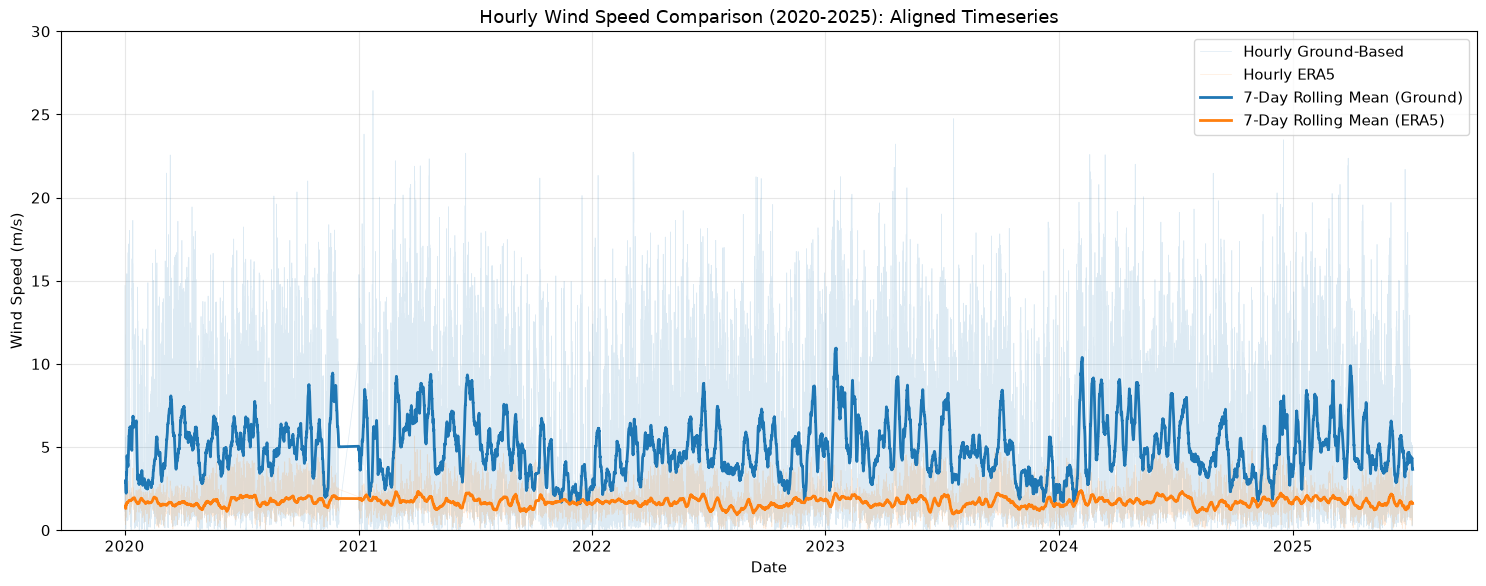

In [6]:
# ============================================================
# 6. PLOT TIME SERIES WITH 7-DAY ROLLING AVERAGE
# ============================================================
plt.figure(figsize=(15, 6))
# Plot hourly speeds in faint color to show raw variance
plt.plot(merged_df['datetime'], merged_df['speed'], color='#1f77b4', alpha=0.15, label='Hourly Ground-Based', linewidth=0.5)
plt.plot(merged_df['datetime'], merged_df['era5_speed'], color='#ff7f0e', alpha=0.15, label='Hourly ERA5', linewidth=0.5)

# 7-day rolling average (aligned hourly data points)
roll_window = 168
plt.plot(merged_df['datetime'], merged_df['speed'].rolling(roll_window, min_periods=24).mean(), 
         color='#1f77b4', label='7-Day Rolling Mean (Ground)', linewidth=2.0)
plt.plot(merged_df['datetime'], merged_df['era5_speed'].rolling(roll_window, min_periods=24).mean(), 
         color='#ff7f0e', label='7-Day Rolling Mean (ERA5)', linewidth=2.0)

plt.title('Hourly Wind Speed Comparison (2020-2025): Aligned Timeseries')
plt.xlabel('Date')
plt.ylabel('Wind Speed (m/s)')
plt.legend(loc='upper right')
plt.ylim(0, 30)
plt.tight_layout()
plt.savefig('../../data/exports/hanle_aligned_timeseries_comparison.png', dpi=150)
plt.show()

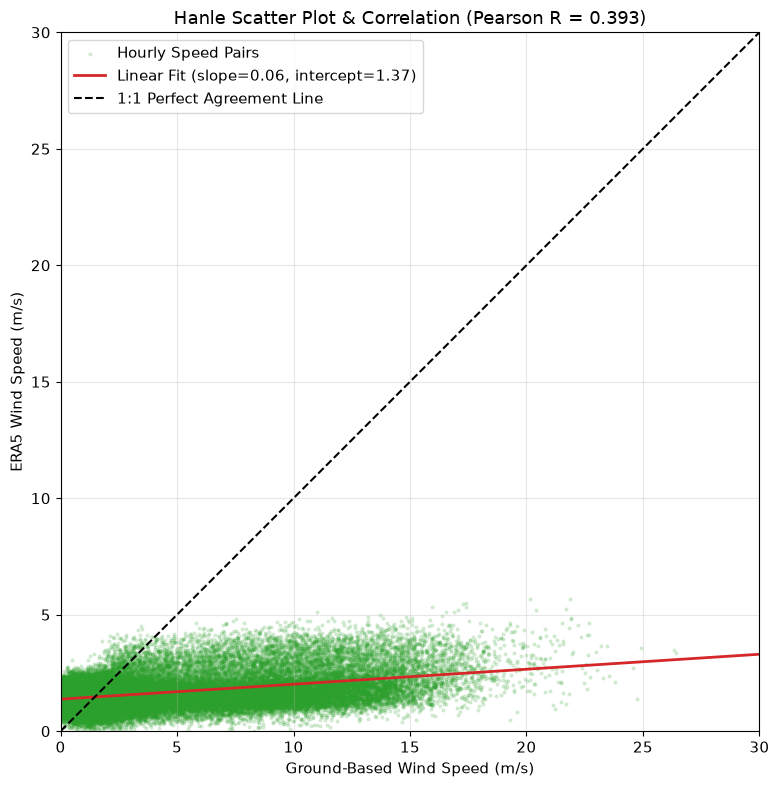

In [7]:
# ============================================================
# 7. SCATTER PLOT AND CORRELATION
# ============================================================
plt.figure(figsize=(8, 8))
plt.scatter(merged_df['speed'], merged_df['era5_speed'], alpha=0.15, s=4, color='#2ca02c', label='Hourly Speed Pairs')

# Fit a trend line
slope, intercept = np.polyfit(merged_df['speed'], merged_df['era5_speed'], 1)
x_vals = np.linspace(0, 30, 100)
plt.plot(x_vals, slope * x_vals + intercept, color='#d62728', linewidth=2.0, 
         label=f'Linear Fit (slope={slope:.2f}, intercept={intercept:.2f})')

# Add 1:1 reference line
plt.plot([0, 30], [0, 30], 'k--', label='1:1 Perfect Agreement Line', linewidth=1.5)

plt.title(f'Hanle Scatter Plot & Correlation (Pearson R = {corr:.3f})')
plt.xlabel('Ground-Based Wind Speed (m/s)')
plt.ylabel('ERA5 Wind Speed (m/s)')
plt.xlim(0, 30)
plt.ylim(0, 30)
plt.gca().set_aspect('equal', adjustable='box')
plt.legend(loc='upper left')
plt.tight_layout()
plt.savefig('../../data/exports/hanle_aligned_scatter_correlation.png', dpi=150)
plt.show()

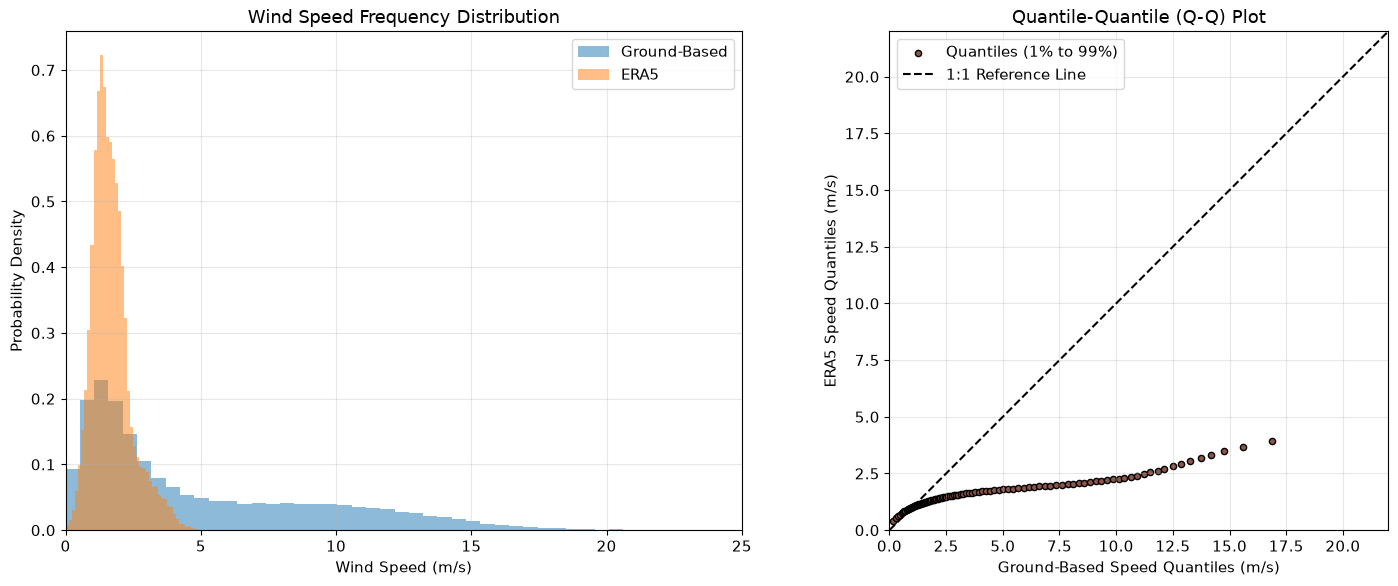

In [8]:
# ============================================================
# 8. DISTRIBUTION COMPARISON (HISTOGRAMS & Q-Q PLOT)
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Panel A: Histograms
axes[0].hist(merged_df['speed'], bins=50, color='#1f77b4', alpha=0.5, label='Ground-Based', density=True)
axes[0].hist(merged_df['era5_speed'], bins=50, color='#ff7f0e', alpha=0.5, label='ERA5', density=True)
axes[0].set_title('Wind Speed Frequency Distribution')
axes[0].set_xlabel('Wind Speed (m/s)')
axes[0].set_ylabel('Probability Density')
axes[0].set_xlim(0, 25)
axes[0].legend()

# Panel B: Quantile-Quantile (Q-Q) Plot
q_values = np.linspace(0.01, 0.99, 99)
q_pub = merged_df['speed'].quantile(q_values)
q_era5 = merged_df['era5_speed'].quantile(q_values)

axes[1].scatter(q_pub, q_era5, color='#8c564b', edgecolor='k', s=20, label='Quantiles (1% to 99%)')
axes[1].plot([0, 25], [0, 25], 'k--', label='1:1 Reference Line')
axes[1].set_title('Quantile-Quantile (Q-Q) Plot')
axes[1].set_xlabel('Ground-Based Speed Quantiles (m/s)')
axes[1].set_ylabel('ERA5 Speed Quantiles (m/s)')
axes[1].set_xlim(0, 22)
axes[1].set_ylim(0, 22)
axes[1].set_aspect('equal', adjustable='box')
axes[1].legend()

plt.tight_layout()
plt.savefig('../../data/exports/hanle_aligned_distribution_comparison.png', dpi=150)
plt.show()

--- Aligned Monthly Means (Excluding ground gaps) ---
 year  month  mean_pub  mean_era5  count
 2020      1  4.397475   1.759936    734
 2020      2  3.719269   1.682054    697
 2020      3  5.961604   1.606395    732
 2020      4  4.756311   1.465442    684
 2020      5  5.027241   1.633906    686
 2020      6  5.234970   1.746423    708
 2020      7  5.616967   1.851640    743
 2020      8  4.678220   1.691571    735
 2020      9  5.523082   1.866277    721
 2020     10  5.522193   1.872947    745
 2020     11  5.205559   1.780932    721
 2020     12  0.903571   2.459477      1
 2021      1  5.095384   1.877261    740
 2021      2  4.729654   1.784086    673
 2021      3  6.313390   1.793643    739
 2021      4  6.762283   1.811560    706
 2021      5  5.278346   1.592166    707
 2021      6  6.376708   1.830949    721
 2021      7  4.977877   1.575016    745
 2021      8  5.754585   1.788419    734
 2021      9  3.801298   1.313762    695
 2021     10  4.384984   1.771516    652
 20

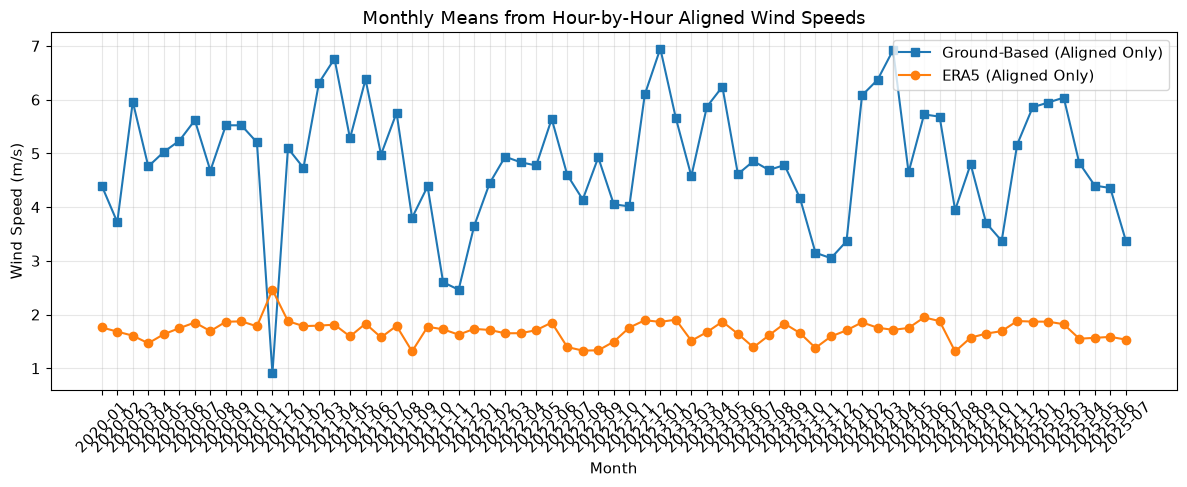

In [9]:
# ============================================================
# 9. RECALCULATED MONTHLY STATS OVER ALIGNED DATA ONLY
# ============================================================
merged_df['year'] = merged_df['datetime'].dt.year
merged_df['month'] = merged_df['datetime'].dt.month

monthly_aligned = merged_df.groupby(['year', 'month']).agg(
    mean_pub=('speed', 'mean'),
    mean_era5=('era5_speed', 'mean'),
    count=('speed', 'count')
).reset_index()

print("--- Aligned Monthly Means (Excluding ground gaps) ---")
print(monthly_aligned.to_string(index=False))

# Plot monthly means
plt.figure(figsize=(12, 5))
monthly_aligned['date_str'] = monthly_aligned['year'].astype(str) + '-' + monthly_aligned['month'].astype(str).str.zfill(2)
plt.plot(monthly_aligned['date_str'], monthly_aligned['mean_pub'], marker='s', color='#1f77b4', label='Ground-Based (Aligned Only)')
plt.plot(monthly_aligned['date_str'], monthly_aligned['mean_era5'], marker='o', color='#ff7f0e', label='ERA5 (Aligned Only)')
plt.title('Monthly Means from Hour-by-Hour Aligned Wind Speeds')
plt.xlabel('Month')
plt.ylabel('Wind Speed (m/s)')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../../data/exports/hanle_aligned_monthly_means.png', dpi=150)
plt.show()